# 02 — Prétraitement des données

## Objectif du notebook

Préparer les données pour l'apprentissage :
1. Nettoyage et noms explicites des colonnes.
2. Suppression des variables inutiles et sélection des capteurs.
3. Calcul du RUL (cible à prédire).
4. *Feature engineering* simple : moyennes mobiles et variations des capteurs.
5. Séparation **par moteur** en ensembles d'entraînement et de validation.
6. Normalisation des données.
7. Sauvegarde des données préparées et des transformations (`preprocessing.pkl`).

**Règle importante :** les fonctions de transformation sont écrites dans `backend/features.py`.
Le notebook et l'application FastAPI utilisent **le même fichier**, donc exactement les mêmes calculs.

## 1. Importations

In [1]:
# Importation des bibliothèques
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.preprocessing import StandardScaler

# Fonctions de préparation partagées avec le backend
sys.path.append("../backend")
from features import (load_cmapss_file, add_rul_column, build_features,
                      get_feature_columns, SELECTED_SENSORS, ROLLING_WINDOW, MAX_RUL)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 90

# Graine aléatoire pour la reproductibilité
RANDOM_STATE = 42

## 2. Chargement et nettoyage

La fonction `load_cmapss_file` lit le fichier texte, supprime les colonnes vides en fin de ligne
et attribue des **noms explicites** aux 26 colonnes.

In [2]:
# Chargement des données
train_data = load_cmapss_file("../data/train_FD001.txt")
test_data = load_cmapss_file("../data/test_FD001.txt")
rul_test = pd.read_csv("../data/RUL_FD001.txt", header=None, names=["true_RUL"])

print("Colonnes :", list(train_data.columns))

Colonnes : ['unit_id', 'cycle', 'op_setting_1', 'op_setting_2', 'op_setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']


## 3. Suppression des variables inutiles

D'après l'analyse exploratoire, on conserve uniquement :
- `unit_id` et `cycle` ;
- les **14 capteurs** qui varient avec la dégradation.

Les 3 paramètres opérationnels et les 7 capteurs constants sont supprimés.

In [3]:
print("Capteurs retenus :", SELECTED_SENSORS)

columns_to_keep = ["unit_id", "cycle"] + SELECTED_SENSORS
train_data = train_data[columns_to_keep]
test_data = test_data[columns_to_keep]

print("Nouvelles dimensions :", train_data.shape)

Capteurs retenus : ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
Nouvelles dimensions : (20631, 16)


## 4. Calcul du RUL (variable cible)

Dans le jeu d'entraînement, chaque moteur fonctionne jusqu'à la panne :

$$RUL = \text{dernier cycle du moteur} - \text{cycle actuel}$$

### RUL plafonné à 125 cycles
L'EDA a montré que les capteurs ne changent presque pas en début de vie.
On applique donc la méthode classique du **RUL linéaire par morceaux** : le RUL est limité
à `MAX_RUL = 125`. Concrètement, le modèle apprend « ce moteur est en pleine santé »
plutôt que d'essayer de deviner un RUL de 250 sans information.

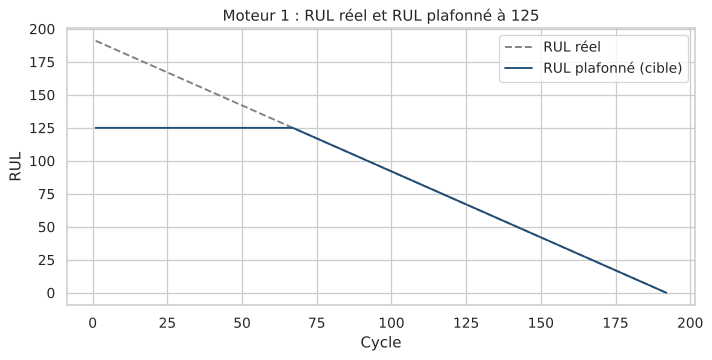

In [4]:
# Ajout de la colonne RUL plafonnée
train_data = add_rul_column(train_data)

# Visualisation sur un moteur
engine_1 = train_data[train_data["unit_id"] == 1]
real_rul = engine_1["cycle"].max() - engine_1["cycle"]

plt.figure(figsize=(9, 4))
plt.plot(engine_1["cycle"], real_rul, "--", label="RUL réel", color="gray")
plt.plot(engine_1["cycle"], engine_1["RUL"], label="RUL plafonné (cible)", color="#1f4e79")
plt.title("Moteur 1 : RUL réel et RUL plafonné à " + str(MAX_RUL))
plt.xlabel("Cycle")
plt.ylabel("RUL")
plt.legend()
plt.show()

## 5. Feature Engineering

Pour chacun des 14 capteurs, la fonction `build_features` crée :

| Variable | Calcul | Intérêt |
|---|---|---|
| `sensor_X` | valeur brute | information instantanée |
| `sensor_X_mean` | moyenne des 10 derniers cycles | réduit le bruit de mesure |
| `sensor_X_trend` | moyenne actuelle − moyenne d'il y a 10 cycles | vitesse de dégradation |

On ajoute aussi le numéro de `cycle` (âge du moteur), connu au moment de la prédiction.

**Pas de fuite de données :** les calculs sont faits moteur par moteur et utilisent uniquement
les cycles **passés** (fenêtre glissante vers l'arrière). Une prédiction au cycle *t* n'utilise
jamais les cycles *t+1, t+2...*

In [5]:
# Construction des variables
train_features = build_features(train_data)
test_features = build_features(test_data)

feature_columns = get_feature_columns()
print("Nombre de variables d'entrée :", len(feature_columns))
print(feature_columns[:7], "...")

Nombre de variables d'entrée : 43
['cycle', 'sensor_2', 'sensor_2_mean', 'sensor_2_trend', 'sensor_3', 'sensor_3_mean', 'sensor_3_trend'] ...


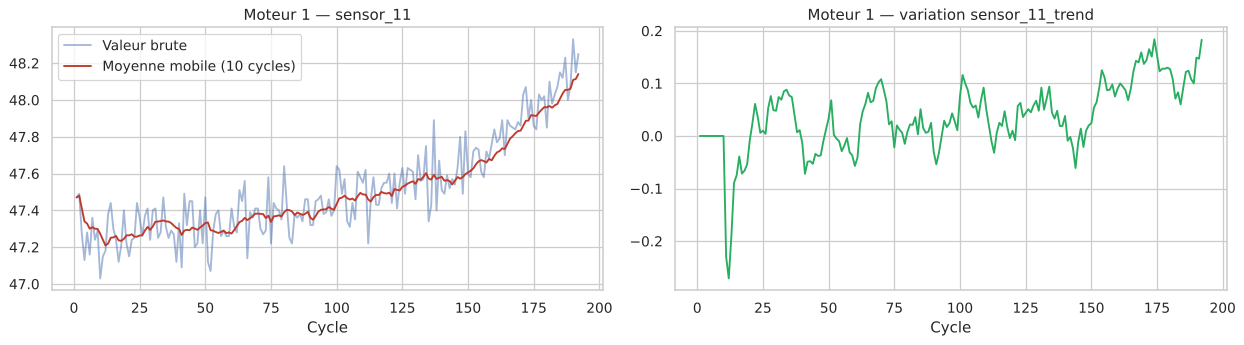

In [6]:
# Comparaison valeur brute / moyenne mobile / tendance pour un moteur
engine_1 = train_features[train_features["unit_id"] == 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(engine_1["cycle"], engine_1["sensor_11"], alpha=0.5, label="Valeur brute")
axes[0].plot(engine_1["cycle"], engine_1["sensor_11_mean"], color="#c0392b",
             label="Moyenne mobile (" + str(ROLLING_WINDOW) + " cycles)")
axes[0].set_title("Moteur 1 — sensor_11")
axes[0].set_xlabel("Cycle")
axes[0].legend()

axes[1].plot(engine_1["cycle"], engine_1["sensor_11_trend"], color="#27ae60")
axes[1].set_title("Moteur 1 — variation sensor_11_trend")
axes[1].set_xlabel("Cycle")
plt.tight_layout()
plt.show()

**Interprétation :** la moyenne mobile supprime une grande partie du bruit et fait clairement
apparaître la dérive du capteur. La variation (`trend`) devient positive et croissante en fin de vie.

## 6. Séparation entraînement / validation par moteur

On sépare les **moteurs** (et non les lignes) : 80 moteurs pour l'entraînement, 20 pour la validation.

Si l'on mélangeait les lignes, des cycles d'un même moteur se retrouveraient dans les deux ensembles :
le modèle « reconnaîtrait » le moteur et les résultats de validation seraient trop optimistes
(**fuite de données**).

Le **jeu de test officiel NASA** est conservé à part pour l'évaluation finale.

In [7]:
# Liste des identifiants de moteurs, mélangée avec une graine fixe
all_engine_ids = train_features["unit_id"].unique()
random_generator = np.random.RandomState(RANDOM_STATE)
shuffled_ids = random_generator.permutation(all_engine_ids)

# 80 % des moteurs pour l'entraînement, 20 % pour la validation
number_of_train_engines = int(len(shuffled_ids) * 0.8)
train_engine_ids = sorted(int(x) for x in shuffled_ids[:number_of_train_engines])
validation_engine_ids = sorted(int(x) for x in shuffled_ids[number_of_train_engines:])

train_set = train_features[train_features["unit_id"].isin(train_engine_ids)]
validation_set = train_features[train_features["unit_id"].isin(validation_engine_ids)]

print("Moteurs d'entraînement :", len(train_engine_ids), "→", len(train_set), "lignes")
print("Moteurs de validation  :", len(validation_engine_ids), "→", len(validation_set), "lignes")
print("Moteurs de validation  :", validation_engine_ids)

# Vérification : aucun moteur commun
common_engines = set(train_engine_ids) & set(validation_engine_ids)
print("Moteurs communs :", len(common_engines))

Moteurs d'entraînement : 80 → 16340 lignes
Moteurs de validation  : 20 → 4291 lignes
Moteurs de validation  : [2, 3, 15, 21, 22, 24, 30, 38, 52, 53, 61, 64, 72, 75, 83, 85, 87, 88, 92, 93]
Moteurs communs : 0


## 7. Préparation du jeu de test officiel

Pour le test, on évalue le modèle au **dernier cycle observé** de chaque moteur,
et on compare la prédiction au RUL réel fourni dans `RUL_FD001.txt`.

In [8]:
# Dernière ligne de chaque moteur de test
test_last_cycles = test_features.groupby("unit_id").tail(1).copy()
test_last_cycles = test_last_cycles.sort_values("unit_id").reset_index(drop=True)

# Ajout du RUL réel (le fichier RUL est dans l'ordre des moteurs 1 à 100)
test_last_cycles["true_RUL"] = rul_test["true_RUL"].values

print("Moteurs de test :", len(test_last_cycles))
test_last_cycles[["unit_id", "cycle", "sensor_11", "sensor_11_mean", "true_RUL"]].head()

Moteurs de test : 100


,unit_id,cycle,sensor_11,sensor_11_mean,true_RUL
0,1,31,47.23,47.288,112
1,2,49,47.67,47.509,98
2,3,126,47.88,47.705,69
3,4,106,47.65,47.630,82
4,5,98,47.46,47.533,91


## 8. Normalisation

Les capteurs ont des échelles très différentes (ex. `sensor_9` ≈ 9000, `sensor_15` ≈ 8,4).
On applique une **standardisation** : $z = \dfrac{x - \mu}{\sigma}$.

- Indispensable pour la **régression linéaire** (coefficients comparables) et **Isolation Forest**.
- Sans effet négatif sur les modèles à base d'arbres.

**Le `StandardScaler` est ajusté uniquement sur les moteurs d'entraînement**, puis appliqué
tel quel à la validation, au test et à l'application.

In [9]:
# Ajustement du scaler sur l'entraînement uniquement
scaler = StandardScaler()
scaler.fit(train_set[feature_columns])

# Vérification sur l'entraînement : moyenne ≈ 0, écart-type ≈ 1
train_scaled = scaler.transform(train_set[feature_columns])
print("Moyenne (5 premières variables)     :", train_scaled.mean(axis=0)[:5].round(3))
print("Écart-type (5 premières variables) :", train_scaled.std(axis=0)[:5].round(3))

Moyenne (5 premières variables)     : [-0. -0.  0.  0.  0.]
Écart-type (5 premières variables) : [1. 1. 1. 1. 1.]


## 9. Sauvegarde

- Les données préparées (non normalisées) sont enregistrées dans `data/processed/`.
- Les transformations sont enregistrées dans `models/preprocessing.pkl` pour être réutilisées
  à l'identique par le backend.

In [10]:
import os
os.makedirs("../data/processed", exist_ok=True)

train_set.to_csv("../data/processed/train_set.csv", index=False)
validation_set.to_csv("../data/processed/validation_set.csv", index=False)
test_last_cycles.to_csv("../data/processed/test_last_cycles.csv", index=False)

# Dictionnaire des transformations
preprocessing = {
    "scaler": scaler,
    "feature_columns": feature_columns,
    "selected_sensors": SELECTED_SENSORS,
    "rolling_window": ROLLING_WINDOW,
    "max_rul": MAX_RUL,
    "train_engine_ids": train_engine_ids,
    "validation_engine_ids": validation_engine_ids,
}
joblib.dump(preprocessing, "../models/preprocessing.pkl")
print("Fichiers sauvegardés.")

Fichiers sauvegardés.


## 10. Conclusion

- 14 capteurs retenus, 43 variables d'entrée (cycle + 14 × 3).
- Cible : RUL plafonné à 125 cycles.
- Séparation **par moteur** (80 / 20) → aucune fuite entre entraînement et validation.
- Normalisation ajustée **uniquement** sur l'entraînement.
- Jeu de test officiel réservé à l'évaluation finale (dernier cycle de chaque moteur).
- Toutes les transformations sont centralisées dans `backend/features.py` et `models/preprocessing.pkl`.